# Мультиклассовая классификация медицинских заключений (RECIST)

**Задача.** По свободному тексту радиологического заключения определить
категорию ответа опухоли на лечение и заполнить два поля для неразмеченных
записей:
- `result` — 4 класса: полный ответ, частичный ответ, стабилизация, прогрессирование;
- `result_general` — 3 укрупнённых: ответ на лечение, стабилизация, прогрессирование.

**Подходы (сравниваются):** baseline (TF-IDF + логистическая регрессия),
дообученный трансформер RuBioRoBERTa, большая языковая модель (Groq) в режиме
few-shot. Лучшей моделью размечаются 5175 неразмеченных заключений.


## 0. Импорты и настройки

In [2]:
import warnings, re, os, pickle, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore")

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Зададим ряд базовых показателей

In [4]:
rand_seed = 42
data_path = "/content/drive/MyDrive/radiation_research_methods_1502.xlsx"
OUTPUT_DIR = "."

min_text_len = 50      # минимальная длина заключения
test_size = 0.15
n_splits = 5
use_masking = True
np.random.seed(rand_seed)

Загрузим наш датасет с мед заключениями

In [5]:
df = pd.read_excel(data_path)
df.head(3)

,patient_id,visit,date,conclusion,result,result_general
0,5943,visit 1,2023-08-04,"Единичные мелкие солидные очаги в лёгких, веро...",Прогрессирование заболевания,Прогрессирование заболевания
1,6154,visit 1,2023-08-06,Прогрессирование заболевания (recist 1.1) - ув...,Прогрессирование заболевания,Прогрессирование заболевания
2,10101698,visit 1,2023-11-30,Состояние после РМЭ справа. Очаги в паренхиме ...,NaN,NaN


### Создадим справочник меток

In [6]:
RESULT_CANON = {
    "полный ответ": "Полный ответ", "частичный ответ": "Частичный ответ",
    "стабилизация заболевания": "Стабилизация заболевания",
    "прогрессирование заболевания": "Прогрессирование заболевания",
}
# 4 класса в 3 укрупнённых
TO_GENERAL = {
    "Полный ответ": "Ответ на лечение", "Частичный ответ": "Ответ на лечение",
    "Стабилизация заболевания": "Стабилизация заболевания",
    "Прогрессирование заболевания": "Прогрессирование заболевания",
}
# паттерны дословных меток в тексте
LEAK_PATTERNS = [
    (r"полн(?:ый|ой|ого|ому|ым|ом)\s+(?:ответ|регресс)[а-я]*",    "<RESPONSE>"),
    (r"частичн(?:ый|ой|ого|ому|ым|ом)\s+(?:ответ|регресс)[а-я]*", "<RESPONSE>"),
    (r"прогрессировани[еяю]\s+заболевани[яею]",                    "<PROGRESSION>"),
    (r"без\s+призна[а-я]+\s+прогрессировани[яе]",                  "<PROGRESSION>"),
    (r"данных\s+за\s+прогрессировани[ея]",                         "<PROGRESSION>"),
    (r"стабилизаци[яиею]\s+(?:заболевани[яею]|процесса)",          "<STABILIZATION>"),
]

SPECIAL_TOKENS = ["<DATE>", "<RESPONSE>", "<PROGRESSION>", "<STABILIZATION>"]

# Предобработка данных

In [7]:
def clean_text(t: str) -> str:
    """Унификация дат и пробелов в тексте заключения"""
    if not isinstance(t, str):
        return ""
    t = re.sub(r"\b\d{1,2}[./-]\d{1,2}[./-]\d{2,4}\b", "<DATE>", t)
    t = re.sub(r"\b(19|20)\d{2}\s*(?:г\.?|года?)\b", "<DATE>", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t


def mask_labels(t: str) -> str:
    """Заменяет дословные упоминания меток на токены"""
    for pat, repl in LEAK_PATTERNS:
        t = re.sub(pat, repl, t, flags=re.IGNORECASE)
    return t


def canon_label(s):

    if not isinstance(s, str) or s.strip() == "" or s.lower() == "nan":
        return np.nan
    return RESULT_CANON.get(s.strip().lower(), s.strip())

В датасете у части заключений врач прямо в тексте пишет вывод словами, которые потом и стали меткой.
Если оставить такие тексты как есть, модель пойдёт по пути наименьшего сопротивления. BERT и LLM очень хорошо ловят такие сигналы и буквально учится правилу «если в тексте есть слова "прогрессирование заболевания" значит класс "прогрессирование"». Я хочу заставить модель учиться по описательной части заключения — по тому, что реально видит рентгенолог. Поэтому я регулярками заменяю дословные упоминания меток на специальные токены-плейсхолдеры

In [8]:
def build_text(df: pd.DataFrame, use_masking: bool):
    df["conclusion_clean"]  = df["conclusion"].apply(clean_text)
    df["conclusion_masked"] = df["conclusion_clean"].apply(mask_labels)
    text_col = "conclusion_masked" if use_masking else "conclusion_clean"
    df["n_chars"] = df[text_col].str.len()
    df["n_words"] = df[text_col].str.split().map(len)
    return df, text_col


def build_targets(df: pd.DataFrame) -> pd.DataFrame:
    """Канонизирует result и детерминированно выводит result_general"""
    df["result"] = df["result"].apply(canon_label)
    mask = df["result"].notna()
    df.loc[mask, "result_general"] = df.loc[mask, "result"].map(TO_GENERAL)
    return df


def split_labeled(df: pd.DataFrame):
    """Делит на размеченные и неразмеченные"""
    labeled   = df[df["result"].notna()].copy()
    unlabeled = df[df["result"].isna()].copy()
    return labeled, unlabeled


def remove_outliers(labeled: pd.DataFrame, text_col: str) -> pd.DataFrame:
    """короткие тексты, точные дубли, противоречивая разметка"""
    n0 = len(labeled)
    labeled = labeled[labeled[text_col].str.len() >= min_text_len]
    labeled = labeled.drop_duplicates(subset=[text_col, "result"])
    conflict = labeled.groupby(text_col)["result"].nunique()
    conflict = conflict[conflict > 1].index                     # один текст ↔ разные метки
    labeled = labeled[~labeled[text_col].isin(conflict)]
    print(f"[outliers] {n0} -> {len(labeled)} (удалено {n0 - len(labeled)})")
    return labeled


def holdout_split(labeled: pd.DataFrame):
    pat = (labeled.groupby("patient_id")["result"]
           .agg(lambda x: x.mode()[0]).reset_index())
    dev_pat, test_pat = train_test_split(
        pat, test_size=test_size, stratify=pat["result"], random_state=rand_seed)
    dev  = labeled[labeled["patient_id"].isin(dev_pat["patient_id"])].copy()
    test = labeled[labeled["patient_id"].isin(test_pat["patient_id"])].copy()
    assert set(dev["patient_id"]).isdisjoint(test["patient_id"]), "утечка пациентов!"
    print(f"[split] dev={len(dev)} | test={len(test)}")
    return dev, test


def make_folds(dev: pd.DataFrame):
    """пациент целиком в одном фолде + баланс классов"""
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=rand_seed)
    folds = []
    for tr_i, va_i in sgkf.split(dev, dev["result"], groups=dev["patient_id"]):
        tr, va = dev.iloc[tr_i].copy(), dev.iloc[va_i].copy()
        assert set(tr["patient_id"]).isdisjoint(va["patient_id"])
        folds.append((tr, va))
    print(f"[cv] {len(folds)} фолдов | пример train/val = "
          f"{len(folds[0][0])}/{len(folds[0][1])}")
    return folds


def run_eda(labeled: pd.DataFrame, text_col: str):
    print("\nresult:\n", labeled["result"].value_counts())
    print("\nresult_general:\n", labeled["result_general"].value_counts())
    print("\nДлина (символы):\n", labeled["n_chars"].describe())
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    labeled["result"].value_counts().plot.barh(ax=ax[0], title="Баланс классов result")
    labeled["n_chars"].clip(upper=2000).hist(bins=50, ax=ax[1])
    ax[1].set_title("Длина заключения, символы")
    plt.tight_layout(); plt.show()


def check_token_length(labeled: pd.DataFrame, text_col: str,
                       model_name="alexyalunin/RuBioRoBERTa"):
    """Опционально: проверка длины в токенах под лимит BERT (512). Нужен интернет."""
    from transformers import AutoTokenizer
    tok = AutoTokenizer.from_pretrained(model_name)
    tok.add_special_tokens({"additional_special_tokens": SPECIAL_TOKENS})
    n_tok = labeled[text_col].map(lambda s: len(tok.encode(s)))
    print(f"[tokens] >512: {(n_tok > 512).sum()} | max={n_tok.max()} | mean={n_tok.mean():.0f}")
    return tok


def save_outputs(labeled, unlabeled, test, folds):
    """Сохраняет очищенные данные и фолды (чтобы зафиксировать предобработку)."""
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    labeled.to_csv(f"{OUTPUT_DIR}/labeled_clean.csv", index=False)
    unlabeled.to_csv(f"{OUTPUT_DIR}/unlabeled_clean.csv", index=False)
    test.to_csv(f"{OUTPUT_DIR}/test_holdout.csv", index=False)
    for i, (tr, va) in enumerate(folds):
        tr.to_csv(f"{OUTPUT_DIR}/fold{i}_train.csv", index=False)
        va.to_csv(f"{OUTPUT_DIR}/fold{i}_val.csv", index=False)
    print(f"[save] файлы записаны в {OUTPUT_DIR}")


Запуск всего пайплайна предобработки (очистка, сплит по пациентам, CV-фолды, EDA):

[data] размечено=2307 | к предсказанию=5175 | text_col=conclusion_masked
[outliers] 2307 -> 2093 (удалено 214)
[split] dev=1764 | test=329
[cv] 5 фолдов | пример train/val = 1415/349

result:
 result
Стабилизация заболевания        1716
Прогрессирование заболевания     224
Полный ответ                      77
Частичный ответ                   76
Name: count, dtype: int64

result_general:
 result_general
Стабилизация заболевания        1716
Прогрессирование заболевания     224
Ответ на лечение                 153
Name: count, dtype: int64

Длина (символы):
 count    2093.000000
mean      432.146202
std       283.008953
min        51.000000
25%       274.000000
50%       400.000000
75%       537.000000
max      5260.000000
Name: n_chars, dtype: float64


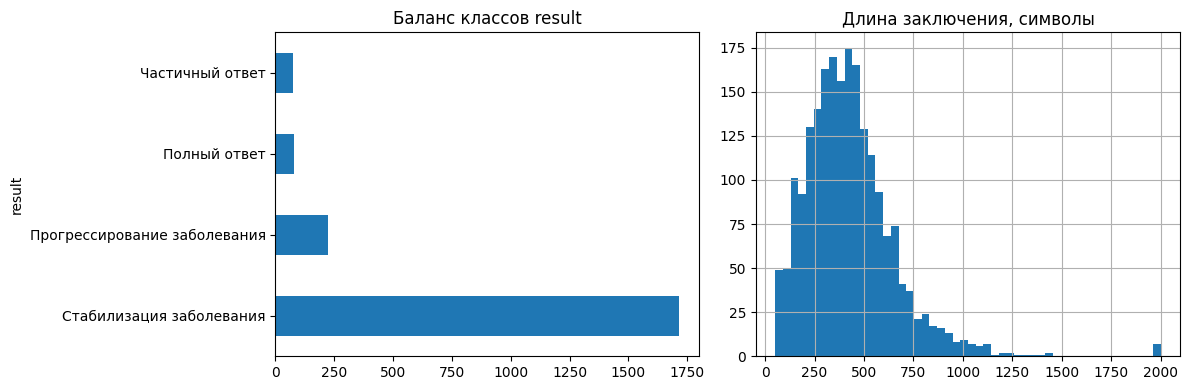

[save] файлы записаны в .


In [9]:
def main(df):
    df, text_col = build_text(df, use_masking)
    df = build_targets(df)
    labeled, unlabeled = split_labeled(df)
    print(f"[data] размечено={len(labeled)} | к предсказанию={len(unlabeled)} | text_col={text_col}")

    labeled = remove_outliers(labeled, text_col)
    dev, test = holdout_split(labeled)
    folds = make_folds(dev)

    run_eda(labeled, text_col)
    # check_token_length(labeled, text_col)   # раскомментируй на Colab (нужен интернет)
    save_outputs(labeled, unlabeled, test, folds)
    return labeled, unlabeled, dev, test, folds, text_col


labeled, unlabeled, dev, test, folds, text_col = main(df)

## 1. Экспорт готовых данных

Сохраняем очищенные выборки на Drive, чтобы при желании обучать BERT в
отдельном ноутбуке без повторной предобработки.

In [10]:
import pickle, os
EXPORT_DIR = "/content/drive/MyDrive/kursach/dataset_export"
os.makedirs(EXPORT_DIR, exist_ok=True)

# таблицы — в CSV (читаются где угодно)
labeled.to_csv(f"{EXPORT_DIR}/labeled.csv", index=False)
unlabeled.to_csv(f"{EXPORT_DIR}/unlabeled.csv", index=False)
dev.to_csv(f"{EXPORT_DIR}/dev.csv", index=False)
test.to_csv(f"{EXPORT_DIR}/test.csv", index=False)

# фолды — это список пар датафреймов, их в один CSV не записать, поэтому pickle
with open(f"{EXPORT_DIR}/folds.pkl", "wb") as f:
    pickle.dump(folds, f)

# и сохраним, какая колонка рабочая
with open(f"{EXPORT_DIR}/meta.pkl", "wb") as f:
    pickle.dump({"text_col": text_col, "use_masking": use_masking}, f)

print("Экспортировано в", EXPORT_DIR)

Экспортировано в /content/drive/MyDrive/kursach/dataset_export


## 2. Baseline — TF-IDF + логистическая регрессия

Оценивается по кросс-валидации (устойчиво, с разбросом) и на тесте
(общая точка сравнения с LLM).

In [11]:
def build_baseline():
    """TF-IDF (слова + символьные n-граммы) + LogReg с балансировкой классов."""
    feats = FeatureUnion([
        ("word", TfidfVectorizer(analyzer="word",    ngram_range=(1, 2),
                                 min_df=3, max_df=0.9, sublinear_tf=True)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5),
                                 min_df=3, sublinear_tf=True)),
    ])
    clf = LogisticRegression(class_weight="balanced", C=1.0,
                             max_iter=2000, random_state=rand_seed)
    return Pipeline([("tfidf", feats), ("clf", clf)])


def cv_baseline(folds, text_col, target="result"):
    """Прогон по CV-фолдам: macro-F1 и per-class F1 со средним ± std."""
    classes = sorted(folds[0][0][target].unique())
    macro, per_class = [], {c: [] for c in classes}
    for tr, va in folds:
        model = build_baseline().fit(tr[text_col], tr[target])
        pred  = model.predict(va[text_col])
        macro.append(f1_score(va[target], pred, average="macro"))
        for c, v in zip(classes, f1_score(va[target], pred, average=None, labels=classes)):
            per_class[c].append(v)
    print(f"[CV {target}] macro-F1 = {np.mean(macro):.3f} ± {np.std(macro):.3f}")
    for c in classes:
        print(f"   {c:<32} F1 = {np.mean(per_class[c]):.3f} ± {np.std(per_class[c]):.3f}")
    return macro


def eval_test(dev, test, text_col, target="result"):
    """Финальная оценка """
    model = build_baseline().fit(dev[text_col], dev[target])
    pred  = model.predict(test[text_col])
    print(f"\n[TEST {target}] macro-F1 = {f1_score(test[target], pred, average='macro'):.3f}")
    print(classification_report(test[target], pred, digits=3, zero_division=0))
    return model, pred


cv_baseline(folds, text_col, "result")
cv_baseline(folds, text_col, "result_general")
model_base, pred_base = eval_test(dev, test, text_col, "result")

[CV result] macro-F1 = 0.476 ± 0.025
   Полный ответ                     F1 = 0.154 ± 0.069
   Прогрессирование заболевания     F1 = 0.547 ± 0.026
   Стабилизация заболевания         F1 = 0.892 ± 0.013
   Частичный ответ                  F1 = 0.312 ± 0.172
[CV result_general] macro-F1 = 0.562 ± 0.022
   Ответ на лечение                 F1 = 0.244 ± 0.069
   Прогрессирование заболевания     F1 = 0.547 ± 0.030
   Стабилизация заболевания         F1 = 0.895 ± 0.015

[TEST result] macro-F1 = 0.611
                              precision    recall  f1-score   support

                Полный ответ      0.308     0.286     0.296        14
Прогрессирование заболевания      0.568     0.636     0.600        33
    Стабилизация заболевания      0.911     0.891     0.901       265
             Частичный ответ      0.600     0.706     0.649        17

                    accuracy                          0.830       329
                   macro avg      0.597     0.630     0.611       329
         

Матрица ошибок baseline на тесте:

In [12]:
import pandas as pd
from sklearn.metrics import confusion_matrix

def show_confusion(model, test, text_col, target="result"):
    classes = sorted(test[target].unique())
    pred = model.predict(test[text_col])
    cm = confusion_matrix(test[target], pred, labels=classes)
    print(pd.DataFrame(cm, index=[f"истина:{c}" for c in classes],
                       columns=[f"пред:{c}" for c in classes]))

show_confusion(model_base, test, text_col, "result")

                                     пред:Полный ответ  \
истина:Полный ответ                                  4   
истина:Прогрессирование заболевания                  1   
истина:Стабилизация заболевания                      8   
истина:Частичный ответ                               0   

                                     пред:Прогрессирование заболевания  \
истина:Полный ответ                                                  2   
истина:Прогрессирование заболевания                                 21   
истина:Стабилизация заболевания                                     14   
истина:Частичный ответ                                               0   

                                     пред:Стабилизация заболевания  \
истина:Полный ответ                                              8   
истина:Прогрессирование заболевания                             10   
истина:Стабилизация заболевания                                236   
истина:Частичный ответ                                    

## 3. RuBioRoBERTa (дообучение)

Русскоязычный биомедицинский трансформер. Требуется GPU-runtime.

> **Важно про обучение.** С `LR=1e-5` первые 1–2 эпохи macro-F1 может стоять
> на месте (модель предсказывает только мажоритарный класс) — это нормальный
> «разогрев», нужно дождаться. Ранняя остановка (`EarlyStoppingCallback`)
> сама подхватит лучший чекпойнт.

In [13]:
!pip install -q transformers datasets accelerate

In [14]:
import torch
from torch import nn
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, EarlyStoppingCallback)
from sklearn.preprocessing import LabelEncoder

MODEL_NAME = "alexyalunin/RuBioRoBERTa"
MAX_LEN    = 256      # медиана  около 130 токенов, 256 покрывает почти всё
LR         = 1e-5
BATCH      = 16
device     = "cuda" if torch.cuda.is_available() else "cpu"

def get_tokenizer():
    tok = AutoTokenizer.from_pretrained(MODEL_NAME)
    tok.add_special_tokens({"additional_special_tokens": SPECIAL_TOKENS})
    tok.truncation_side = "left"      # сохраняем хвост (вывод заключения)
    return tok

print("device =", device)

device = cuda


In [15]:
class TextDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels, tok):
        self.enc = tok(list(texts), truncation=True, max_length=MAX_LEN,
                       padding="max_length", return_tensors="pt")
        self.labels = torch.tensor(labels, dtype=torch.long)
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = self.labels[i]
        return item

def make_encoder(target_series):
    le = LabelEncoder().fit(sorted(target_series.dropna().unique()))
    return le

In [16]:
class WeightedTrainer(Trainer):
    def __init__(self, class_weights=None, **kw):
        super().__init__(**kw)
        self.class_weights = class_weights
    def compute_loss(self, model, inputs, return_outputs=False, **kw):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss = nn.functional.cross_entropy(
            outputs.logits, labels, weight=self.class_weights.to(model.device))
        return (loss, outputs) if return_outputs else loss

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    pred = logits.argmax(-1)
    return {"macro_f1": f1_score(labels, pred, average="macro")}

Смягчённые веса классов против дисбаланса (`beta=0.5` — компромисс: редкие классы усилены, большинство не проседает)

In [17]:
def softened_weights(y, beta=0.5):
    counts = np.bincount(y, minlength=len(np.unique(y)))
    w = (1.0 / counts) ** beta
    w = w / w.mean()
    return torch.tensor(w, dtype=torch.float)

Обучение модели

In [18]:
Ёimport inspect
_ta_params = set(inspect.signature(TrainingArguments.__init__).parameters)

def train_bert(train_df, val_df, text_col, target, le, run_name="bert"):
    tok = get_tokenizer()
    y_tr = le.transform(train_df[target]); y_va = le.transform(val_df[target])
    ds_tr = TextDataset(train_df[text_col], y_tr, tok)
    ds_va = TextDataset(val_df[text_col],   y_va, tok)

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=len(le.classes_))
    model.resize_token_embeddings(len(tok))

    cw = softened_weights(y_tr, beta=0.5)

    # общие аргументы
    kwargs = dict(
        output_dir=f"{OUTPUT_DIR}/{run_name}", learning_rate=LR,
        per_device_train_batch_size=BATCH, per_device_eval_batch_size=32,
        num_train_epochs=8, save_strategy="epoch",
        load_best_model_at_end=True, metric_for_best_model="macro_f1",
        warmup_steps=100, weight_decay=0.01, logging_steps=50,
        report_to="none", seed=rand_seed)

    # имя аргумента eval-стратегии зависит от версии transformers
    if "eval_strategy" in _ta_params:
        kwargs["eval_strategy"] = "epoch"
    else:
        kwargs["evaluation_strategy"] = "epoch"

    args = TrainingArguments(**kwargs)

    trainer = WeightedTrainer(
        class_weights=cw, model=model, args=args,
        train_dataset=ds_tr, eval_dataset=ds_va,
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])
    trainer.train()

    pred = trainer.predict(ds_va).predictions.argmax(-1)
    print(f"[{run_name}] macro-F1 = {f1_score(y_va, pred, average='macro'):.3f}")
    for c, v in zip(le.classes_, f1_score(y_va, pred, average=None,
                                          labels=np.arange(len(le.classes_)))):
        print(f"   {c:<32} F1 = {v:.3f}")
    return trainer, tok, le

In [19]:
def predict_df(trainer, tok, le, df, text_col):
    """Предсказание меток для произвольного датафрейма."""
    ds = TextDataset(df[text_col], np.zeros(len(df), dtype=int), tok)
    ids = trainer.predict(ds).predictions.argmax(-1)
    return le.inverse_transform(ids)

### 3.1. CV-оценка BERT *(опционально, дорого)*

5 обучений по фолдам, агрегирует macro-F1 как `mean ± std` — прямая аналогия
`cv_baseline`. Порядка 2 часов на GPU. Ячейка ниже с вызовом закомментирована;
раскомментируй, если нужна CV-оценка BERT для сравнения с baseline.

In [20]:
def cv_bert(folds, text_col, target="result"):
    le = make_encoder(folds[0][0][target])
    scores = []
    for i, (tr, va) in enumerate(folds):
        trainer, tok, le = train_bert(tr, va, text_col, target, le, run_name=f"fold{i}")
        pred = predict_df(trainer, tok, le, va, text_col)
        scores.append(f1_score(va[target], pred, average="macro"))
        del trainer; torch.cuda.empty_cache()   # освобождаем память между фолдами
    print(f"\n[CV BERT {target}] macro-F1 = {np.mean(scores):.3f} ± {np.std(scores):.3f}")
    return float(np.mean(scores))

# bert_cv = cv_bert(folds, text_col, "result")

### 3.2. Финальное обучение на dev и оценка на тесте

In [21]:
le = make_encoder(dev["result"])
trainer, tok, le = train_bert(dev, test, text_col, "result", le, run_name="final")

test_pred = predict_df(trainer, tok, le, test, text_col)
bert_test = f1_score(test["result"], test_pred, average="macro")
print(f"\n[TEST result] macro-F1 = {bert_test:.3f}")
print(classification_report(test["result"], test_pred, digits=3, zero_division=0))

config.json:   0%|          | 0.00/786 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.71M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.37M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.18M [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[final] macro-F1 = 0.536
   Полный ответ                     F1 = 0.182
   Прогрессирование заболевания     F1 = 0.618
   Стабилизация заболевания         F1 = 0.894
   Частичный ответ                  F1 = 0.452



[TEST result] macro-F1 = 0.536
                              precision    recall  f1-score   support

                Полный ответ      0.250     0.143     0.182        14
Прогрессирование заболевания      0.600     0.636     0.618        33
    Стабилизация заболевания      0.882     0.906     0.894       265
             Частичный ответ      0.500     0.412     0.452        17

                    accuracy                          0.821       329
                   macro avg      0.558     0.524     0.536       329
                weighted avg      0.807     0.821     0.813       329



Матрица ошибок RuBioRoBERTa на тесте:

In [22]:
cls = sorted(test["result"].unique())
cm = confusion_matrix(test["result"], test_pred, labels=cls)
pd.DataFrame(cm, index=[f"ист:{c}" for c in cls], columns=[f"пр:{c}" for c in cls])

,пр:Полный ответ,пр:Прогрессирование заболевания,пр:Стабилизация заболевания,пр:Частичный ответ
ист:Полный ответ,2,1,11,0
ист:Прогрессирование заболевания,0,21,12,0
ист:Стабилизация заболевания,6,12,240,7
ист:Частичный ответ,0,1,9,7


Сохранение модели на Drive (лучший чекпойнт + токенизатор + LabelEncoder):

In [ ]:
SAVE_DIR = "/content/drive/MyDrive/kursach/rubioroberta_final"
os.makedirs(SAVE_DIR, exist_ok=True)
trainer.save_model(SAVE_DIR)
tok.save_pretrained(SAVE_DIR)
with open(f"{SAVE_DIR}/label_encoder.pkl", "wb") as f:
    pickle.dump(le, f)
print("сохранено в", SAVE_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

сохранено в /content/drive/MyDrive/kursach/rubioroberta_final


### 3.3. Абляция: маскирование утечки

Та же модель на **немаскированном** тексте (`conclusion_clean`) при прочих
равных — оцениваем вклад маскирования.

In [ ]:
# # почистим гпу
# import torch, gc

# # удаляем крупные объекты из памяти, если они есть
# for name in ["trainer", "model", "trainer_nm"]:
#     if name in globals():
#         del globals()[name]
# gc.collect()
# torch.cuda.empty_cache()

# # проверка: сколько теперь свободно
# free, total = torch.cuda.mem_get_info()
# print(f"свободно на GPU: {free/1e9:.1f} / {total/1e9:.1f} ГБ")

свободно на GPU: 15.5 / 15.6 ГБ


In [ ]:
le_nm = make_encoder(dev["result"])
trainer_nm, tok_nm, le_nm = train_bert(
    dev, test, "conclusion_clean", "result", le_nm, run_name="final_nomask")

test_pred_nm = predict_df(trainer_nm, tok_nm, le_nm, test, "conclusion_clean")
print(f"\n[TEST no-mask] macro-F1 = {f1_score(test['result'], test_pred_nm, average='macro'):.3f}")
print(classification_report(test["result"], test_pred_nm, digits=3, zero_division=0))

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: alexyalunin/RuBioRoBERTa
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Macro F1
1,1.186522,1.327096,0.223064
2,1.135113,1.293183,0.223064
3,1.188988,1.227313,0.223064


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[final_nomask] macro-F1 = 0.223
   Полный ответ                     F1 = 0.000
   Прогрессирование заболевания     F1 = 0.000
   Стабилизация заболевания         F1 = 0.892
   Частичный ответ                  F1 = 0.000



[TEST no-mask] macro-F1 = 0.223
                              precision    recall  f1-score   support

                Полный ответ      0.000     0.000     0.000        14
Прогрессирование заболевания      0.000     0.000     0.000        33
    Стабилизация заболевания      0.805     1.000     0.892       265
             Частичный ответ      0.000     0.000     0.000        17

                    accuracy                          0.805       329
                   macro avg      0.201     0.250     0.223       329
                weighted avg      0.649     0.805     0.719       329



## 4. Разметка неразмеченных данных (цель работы)

Лучшей моделью (RuBioRoBERTa) заполняем `result` для 5175 неразмеченных
заключений; `result_general` выводим **детерминированно** из иерархии — так
две метки всегда согласованы. Итог: единый файл, где видно, что размечено
врачом, а что моделью.

In [23]:
import pickle, torch, gc
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer

# освобождаем память от абляционной модели, если висит
for name in ["trainer_nm", "model"]:
    if name in globals(): del globals()[name]
gc.collect(); torch.cuda.empty_cache()

SAVE_DIR = "/content/drive/MyDrive/kursach/rubioroberta_final"
model = AutoModelForSequenceClassification.from_pretrained(SAVE_DIR).to(device)
tok   = AutoTokenizer.from_pretrained(SAVE_DIR)
with open(f"{SAVE_DIR}/label_encoder.pkl", "rb") as f:
    le = pickle.load(f)

infer = Trainer(model=model)

def predict_saved(df, text_col):
    ds = TextDataset(df[text_col], np.zeros(len(df), dtype=int), tok)
    ids = infer.predict(ds).predictions.argmax(-1)
    return le.inverse_transform(ids)

# разметка неразмеченных — маскированным текстом (как при обучении)
unlabeled["result"] = predict_saved(unlabeled, text_col)
unlabeled["result_general"] = unlabeled["result"].map(TO_GENERAL)

print("Размечено:", len(unlabeled))
print("\nРаспределение result:\n", unlabeled["result"].value_counts())
print("\nРаспределение result_general:\n", unlabeled["result_general"].value_counts())

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Размечено: 5175

Распределение result:
 result
Стабилизация заболевания        4275
Прогрессирование заболевания     677
Полный ответ                     122
Частичный ответ                  101
Name: count, dtype: int64

Распределение result_general:
 result_general
Стабилизация заболевания        4275
Прогрессирование заболевания     677
Ответ на лечение                 223
Name: count, dtype: int64


In [24]:
#  истина (врач) + предсказания (модель), с пометкой источника
cols = ["patient_id", "visit", "date", "conclusion", "result", "result_general"]
lab_out = labeled[cols].copy();     lab_out["source"] = "истина"
unl_out = unlabeled[cols].copy();   unl_out["source"] = "предсказание"

final = pd.concat([lab_out, unl_out], ignore_index=True)
final.to_excel("/content/drive/MyDrive/kursach/final_labeled.xlsx", index=False)
print("Итоговый файл сохранён:", len(final), "заключений")

Итоговый файл сохранён: 7268 заключений


## 5. LLM через Groq (few-shot, без дообучения)

Классификация по инструкции и примерам в промпте, на СЫРОМ тексте
`conclusion` (маскирование не нужно). Требуется `GROQ_API_KEY` в Colab Secrets.

In [30]:
!pip install -q groq

from groq import Groq
from google.colab import userdata
import time, collections, json
import pandas as pd
from sklearn.metrics import f1_score, classification_report

client = Groq(api_key=userdata.get("GROQ_API_KEY"))

CLASSES = ["Полный ответ", "Частичный ответ",
           "Стабилизация заболевания", "Прогрессирование заболевания"]

In [34]:
#  базовый промпт (краткие определения классов)
PROMPT_BASE = """Определи категорию ответа опухоли по заключению (RECIST 1.1).
Ответь ровно одним из: Полный ответ | Частичный ответ | Стабилизация заболевания | Прогрессирование заболевания.
Полный — очаги исчезли. Частичный — уменьшились/регрессия. Стабилизация — без динамики. Прогрессирование — рост/новые очаги.
Только название категории."""

# промпт с приоритетами (акцент на стабилизацию по умолчанию)
PROMPT_PRIORITY = """Определи категорию ответа опухоли по заключению (RECIST 1.1).
Ответь ровно одним из: Полный ответ | Частичный ответ | Стабилизация заболевания | Прогрессирование заболевания.

Стабилизация — если нет явной динамики (по умолчанию, самый частый случай).
Прогрессирование — только при явном росте/новых очагах.
Частичный ответ — только при явном уменьшении/регрессии.
Полный ответ — только если очаги полностью исчезли.

Не выбирай активный класс без явных слов о динамике. Только название категории."""

SYSTEM_PROMPT = PROMPT_PRIORITY   # для смены промпта

In [35]:
def parse_class(text):
    """Берём ПОСЛЕДНЕЕ совпадение с классом (у reasoning-моделей ответ в конце)."""
    found = [(text.lower().rfind(c.lower()), c) for c in CLASSES]
    found = [(p, c) for p, c in found if p >= 0]
    return max(found)[1] if found else "Стабилизация заболевания"

def groq_classify(text, model, max_retries=6):
    for attempt in range(max_retries):
        try:
            resp = client.chat.completions.create(
                model=model, temperature=0, max_tokens=64, timeout=60,
                reasoning_effort="low",              # без этого reasoning-модели ~60 сек/запрос
                messages=[{"role":"system","content":SYSTEM_PROMPT},
                          {"role":"user","content":text[:1500]}])
            return parse_class(resp.choices[0].message.content or ""), True
        except Exception as e:
            if "429" in str(e) or "rate" in str(e).lower():
                time.sleep(3 * (attempt + 1))       # ждём при лимите
            else:
                time.sleep(1)
    return "Стабилизация заболевания", False          # фолбэк при сбое

def llm_eval(test_df, model, sleep=0.3):
    preds, fails = [], 0
    for i, t in enumerate(test_df["conclusion"].tolist()):
        p, ok = groq_classify(str(t), model)
        preds.append(p); fails += (not ok)
        time.sleep(sleep)
        if (i+1) % 50 == 0:
            print(f"  {i+1}/{len(test_df)}  (фолбэков: {fails})")
    macro = f1_score(test_df["result"], preds, average="macro")
    print(f"\n[{model}] macro-F1 = {macro:.3f} | фолбэков: {fails}/{len(preds)}")
    print(collections.Counter(preds))               # проверка: разнообразны ли ответы
    print(classification_report(test_df["result"], preds, digits=3, zero_division=0))
    return preds, macro

In [33]:
LLM_MODELS = ["openai/gpt-oss-20b", "openai/gpt-oss-120b"]

llm_scores = {}
for m in LLM_MODELS:
    print(f"\n=== {m} ===")
    preds, macro = llm_eval(test, m)
    llm_scores[m] = macro
    out = test[["patient_id", "conclusion", "result"]].copy()
    out["pred"] = preds
    out.to_csv(f"/content/drive/MyDrive/kursach/llm_{m.replace('/', '_')}.csv", index=False)

# сводка
with open("/content/drive/MyDrive/kursach/llm_scores.json", "w") as f:
    json.dump(llm_scores, f, ensure_ascii=False, indent=2)

print("\n=== ИТОГ (macro-F1) ===")
for m, s in sorted(llm_scores.items(), key=lambda x: -x[1]):
    print(f"{s:.3f}  {m}")


=== openai/gpt-oss-20b ===
  50/329  (фолбэков: 0)
  100/329  (фолбэков: 0)
  150/329  (фолбэков: 0)
  200/329  (фолбэков: 0)
  250/329  (фолбэков: 0)
  300/329  (фолбэков: 0)

[openai/gpt-oss-20b] macro-F1 = 0.424 | фолбэков: 0/329
Counter({'Стабилизация заболевания': 235, 'Прогрессирование заболевания': 54, 'Частичный ответ': 39, 'Полный ответ': 1})
                              precision    recall  f1-score   support

                Полный ответ      0.000     0.000     0.000        14
Прогрессирование заболевания      0.389     0.636     0.483        33
    Стабилизация заболевания      0.872     0.774     0.820       265
             Частичный ответ      0.282     0.647     0.393        17

                    accuracy                          0.720       329
                   macro avg      0.386     0.514     0.424       329
                weighted avg      0.756     0.720     0.729       329


=== openai/gpt-oss-120b ===
  50/329  (фолбэков: 0)
  100/329  (фолбэков: 0)
  15

Другой промпт

In [36]:
# рабочие на free tier модели (Llama 3.3 и Qwen3 сняты с раздачи в процессе работы)
LLM_MODELS = ["openai/gpt-oss-20b", "openai/gpt-oss-120b"]

llm_scores = {}
for m in LLM_MODELS:
    print(f"\n=== {m} ===")
    preds, macro = llm_eval(test, m)
    llm_scores[m] = macro
    out = test[["patient_id", "conclusion", "result"]].copy()
    out["pred"] = preds
    out.to_csv(f"/content/drive/MyDrive/kursach/llm_{m.replace('/', '_')}.csv", index=False)

# сводка
with open("/content/drive/MyDrive/kursach/llm_scores.json", "w") as f:
    json.dump(llm_scores, f, ensure_ascii=False, indent=2)

print("\n=== ИТОГ (macro-F1) ===")
for m, s in sorted(llm_scores.items(), key=lambda x: -x[1]):
    print(f"{s:.3f}  {m}")


=== openai/gpt-oss-20b ===
  50/329  (фолбэков: 0)
  100/329  (фолбэков: 0)
  150/329  (фолбэков: 0)
  200/329  (фолбэков: 0)
  250/329  (фолбэков: 9)


KeyboardInterrupt: 

# Руберта дооьучение

In [ ]:
import gc
for n in ["trainer","model"]:
    if n in globals(): del globals()[n]
gc.collect(); torch.cuda.empty_cache()

MODEL_NAME = "alexyalunin/RuBioRoBERTa"
save_dir = "/content/drive/MyDrive/kursach/rubioroberta_v2"

tok = get_tokenizer()
le = make_encoder(dev["result"])
y_tr = le.transform(dev["result"]); y_va = le.transform(test["result"])
ds_tr = TextDataset(dev[text_col], y_tr, tok)
ds_va = TextDataset(test[text_col], y_va, tok)

model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=4)
model.resize_token_embeddings(len(tok))
cw = softened_weights(y_tr, beta=0.5)

args = TrainingArguments(
    output_dir=save_dir, learning_rate=1e-5,
    per_device_train_batch_size=16, per_device_eval_batch_size=32,
    num_train_epochs=12, eval_strategy="epoch", save_strategy="epoch",
    load_best_model_at_end=True, metric_for_best_model="macro_f1",
    warmup_steps=150, weight_decay=0.01, logging_steps=50,
    report_to="none", seed=42)

trainer = WeightedTrainer(class_weights=cw, model=model, args=args,
    train_dataset=ds_tr, eval_dataset=ds_va, compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=5)])
trainer.train()

test_pred = predict_df(trainer, tok, le, test, text_col)
print("RuBioRoBERTa v2 test macro-F1 =",
      round(f1_score(test["result"], test_pred, average="macro"), 3))
print(classification_report(test["result"], test_pred, digits=3, zero_division=0))

trainer.save_model(save_dir); tok.save_pretrained(save_dir)
with open(f"{save_dir}/label_encoder.pkl","wb") as f: pickle.dump(le, f)
print("сохранено в", save_dir)

config.json:   0%|          | 0.00/786 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.71M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.37M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.18M [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

# Финал с абляцией

In [37]:
import gc, pickle, os
from sklearn.metrics import f1_score, classification_report

def train_eval_save(model_name, text_column, save_name, patience=5):
    """Обучает на dev, оценивает на test, сохраняет. Возвращает macro-F1."""
    global MODEL_NAME
    MODEL_NAME = model_name
    for n in ["trainer","model"]:
        if n in globals(): del globals()[n]
    gc.collect(); torch.cuda.empty_cache()

    le = make_encoder(dev["result"])
    y_tr = le.transform(dev["result"]); y_va = le.transform(test["result"])
    ds_tr = TextDataset(dev[text_column], y_tr, get_tokenizer())
    tok = get_tokenizer()
    ds_tr = TextDataset(dev[text_column], y_tr, tok)
    ds_va = TextDataset(test[text_column], y_va, tok)

    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=4)
    model.resize_token_embeddings(len(tok))
    cw = softened_weights(y_tr, beta=0.5)

    save_dir = f"/content/drive/MyDrive/kursach/{save_name}"
    args = TrainingArguments(
        output_dir=save_dir, learning_rate=1e-5,
        per_device_train_batch_size=16, per_device_eval_batch_size=32,
        num_train_epochs=12, eval_strategy="epoch", save_strategy="epoch",
        load_best_model_at_end=True, metric_for_best_model="macro_f1",
        warmup_steps=150, weight_decay=0.01, logging_steps=50,
        report_to="none", seed=42, save_total_limit=1)

    trainer = WeightedTrainer(class_weights=cw, model=model, args=args,
        train_dataset=ds_tr, eval_dataset=ds_va, compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=patience)])
    trainer.train()

    pred = le.inverse_transform(trainer.predict(ds_va).predictions.argmax(-1))
    macro = f1_score(test["result"], pred, average="macro")
    print(f"\n>>> {save_name}: macro-F1 = {macro:.3f}")
    print(classification_report(test["result"], pred, digits=3, zero_division=0))

    trainer.save_model(save_dir); tok.save_pretrained(save_dir)
    with open(f"{save_dir}/label_encoder.pkl","wb") as f: pickle.dump(le, f)
    print(">>> сохранено в", save_dir)
    return macro

In [38]:
# # 1. RuBioRoBERTa — финал с терпеливым обучением (маскированный текст)
# m_bert = train_eval_save("alexyalunin/RuBioRoBERTa", text_col, "rubioroberta_final")

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: alexyalunin/RuBioRoBERTa
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Macro F1
1,1.191853,1.307196,0.223064
2,1.081326,1.160076,0.296674
3,0.991557,1.005483,0.383153
4,0.806159,0.979447,0.448378
5,0.617141,0.974732,0.604268
6,0.543178,0.989128,0.576512
7,0.422058,1.097826,0.593877
8,0.284058,1.071194,0.614071


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

RuntimeError: [enforce fail at inline_container.cc:672] . unexpected pos 2597154368 vs 2597154260

In [39]:
import os
for f in sorted(os.listdir("/content/drive/MyDrive/kursach")):
    path = f"/content/drive/MyDrive/kursach/{f}"
    size = os.path.getsize(path) if os.path.isfile(path) else "папка"
    print(f"{f:45} {size}")

dataset_export                                папка
final                                         папка
final_labeled.xlsx                            1830042
llm_gptoss20b_preds.csv                       299028
llm_llama-3.3-70b-versatile.csv               298376
llm_llama33_70b_preds.csv                     298572
llm_openai_gpt-oss-120b.csv                   298802
llm_openai_gpt-oss-20b.csv                    298912
llm_qwen_qwen3-32b.csv                        298490
llm_scores.json                               92
results_summary.json                          112
rubioroberta_final                            папка
rubioroberta_v2                               папка
ruroberta_large                               папка
ruroberta_metrics.json                        1090
ruroberta_training_log.csv                    3606
